# 01 · Overview: inverter PV vs satellite GTI over time

Raw 1-minute inverter readings next to Open-Meteo `satellite_radiation_seamless` irradiance. Points are coloured by the curtailment state from `src/inverter_app/curtailment.py`: only **unconstrained** readings show the power the panels could give.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from common import load_joined, load_satellite, load_snapshots

TZ = "Europe/Kyiv"
plt.rcParams["figure.figsize"] = (13, 4)
plt.rcParams["axes.grid"] = True
STATE_COLORS = {
    "unconstrained": "tab:green",
    "curtailed": "tab:red",
    "unknown": "tab:orange",
    "dark": "lightgray",
}

In [2]:
snapshots = load_snapshots()
satellite = load_satellite()
start, end = snapshots.index.min(), snapshots.index.max()
satellite = satellite.loc[start:end]
print(f"snapshots: {len(snapshots)} rows, {start} … {end}")
print(f"satellite: {len(satellite)} rows, "
      f"{satellite['global_tilted_irradiance'].isna().sum()} empty")
snapshots["state"].value_counts()

snapshots: 14975 rows, 2026-10-25 09:45:56.585000+00:00 … 2026-11-04 20:27:00.855025+00:00
satellite: 1504 rows, 4 empty


state
dark             10358
unconstrained     4513
curtailed          104
Name: count, dtype: int64

## Whole period

PV power (left axis) and GTI (right axis). Battery charge and grid voltage below: grid voltage near 0 marks outages, when PV can only feed the load and the battery.

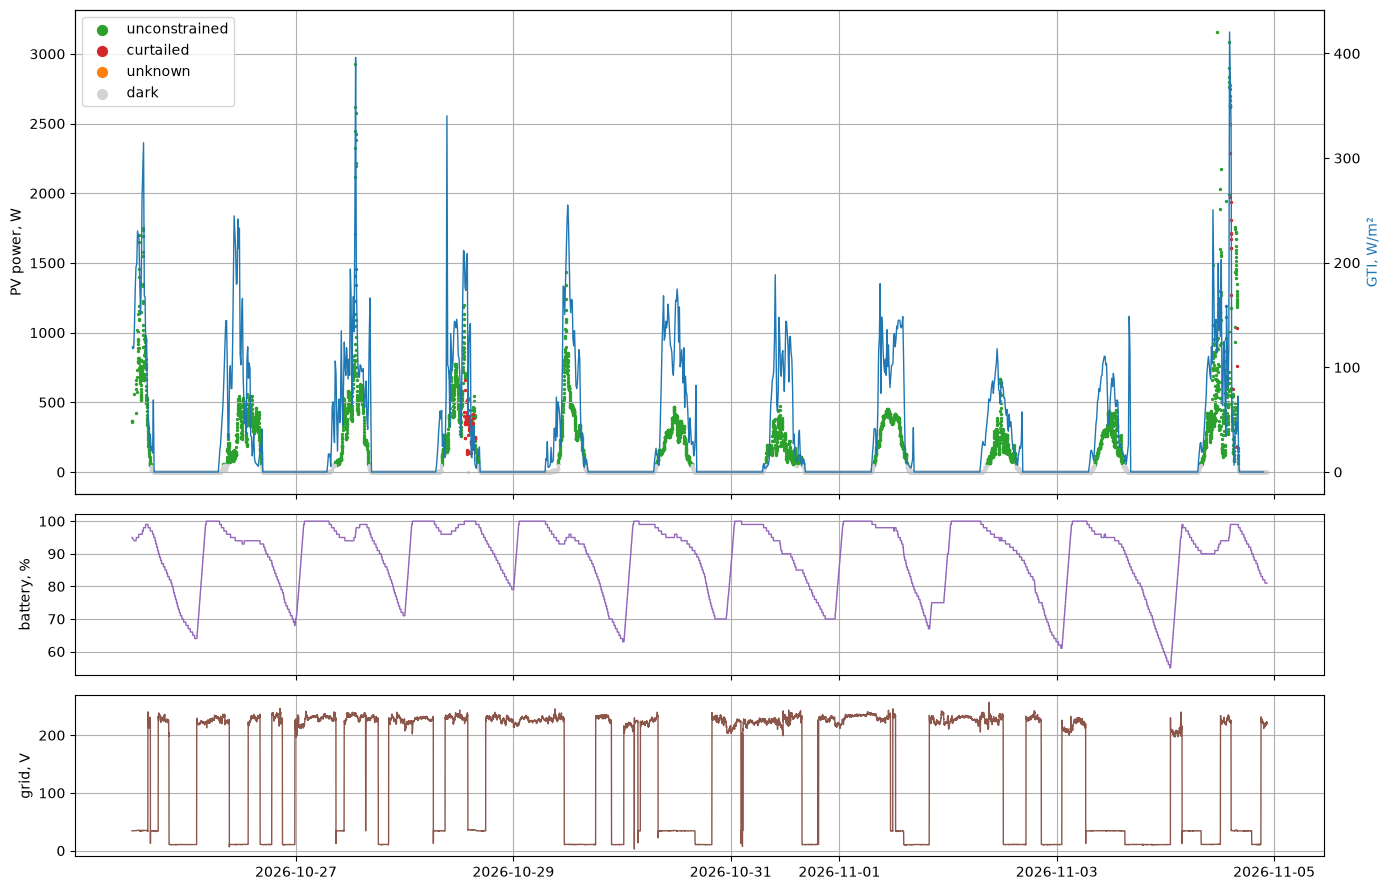

In [3]:
fig, (ax, ax_soc, ax_grid) = plt.subplots(
    3, 1, figsize=(14, 9), sharex=True,
    gridspec_kw={"height_ratios": [3, 1, 1]},
)
local = snapshots.tz_convert(TZ)
for state, color in STATE_COLORS.items():
    part = local[local["state"] == state]
    ax.scatter(part.index, part["solar_power_w"], s=2, c=color, label=state)
ax.set_ylabel("PV power, W")
ax.legend(loc="upper left", markerscale=5)
ax_gti = ax.twinx()
ax_gti.plot(
    satellite.tz_convert(TZ)["global_tilted_irradiance"],
    c="tab:blue", lw=1, label="GTI",
)
ax_gti.set_ylabel("GTI, W/m²", color="tab:blue")
ax_gti.grid(False)
ax_soc.plot(local["battery_charge_pct"], c="tab:purple", lw=1)
ax_soc.set_ylabel("battery, %")
ax_grid.plot(local["grid_voltage_v"], c="tab:brown", lw=1)
ax_grid.set_ylabel("grid, V")
fig.tight_layout()

## Day by day

One panel per day. The GTI line is scaled to PV power by the median W per W/m² over unconstrained readings, so on a well-behaved day the two curves should overlap.

median scale: 3.10 W per W/m²


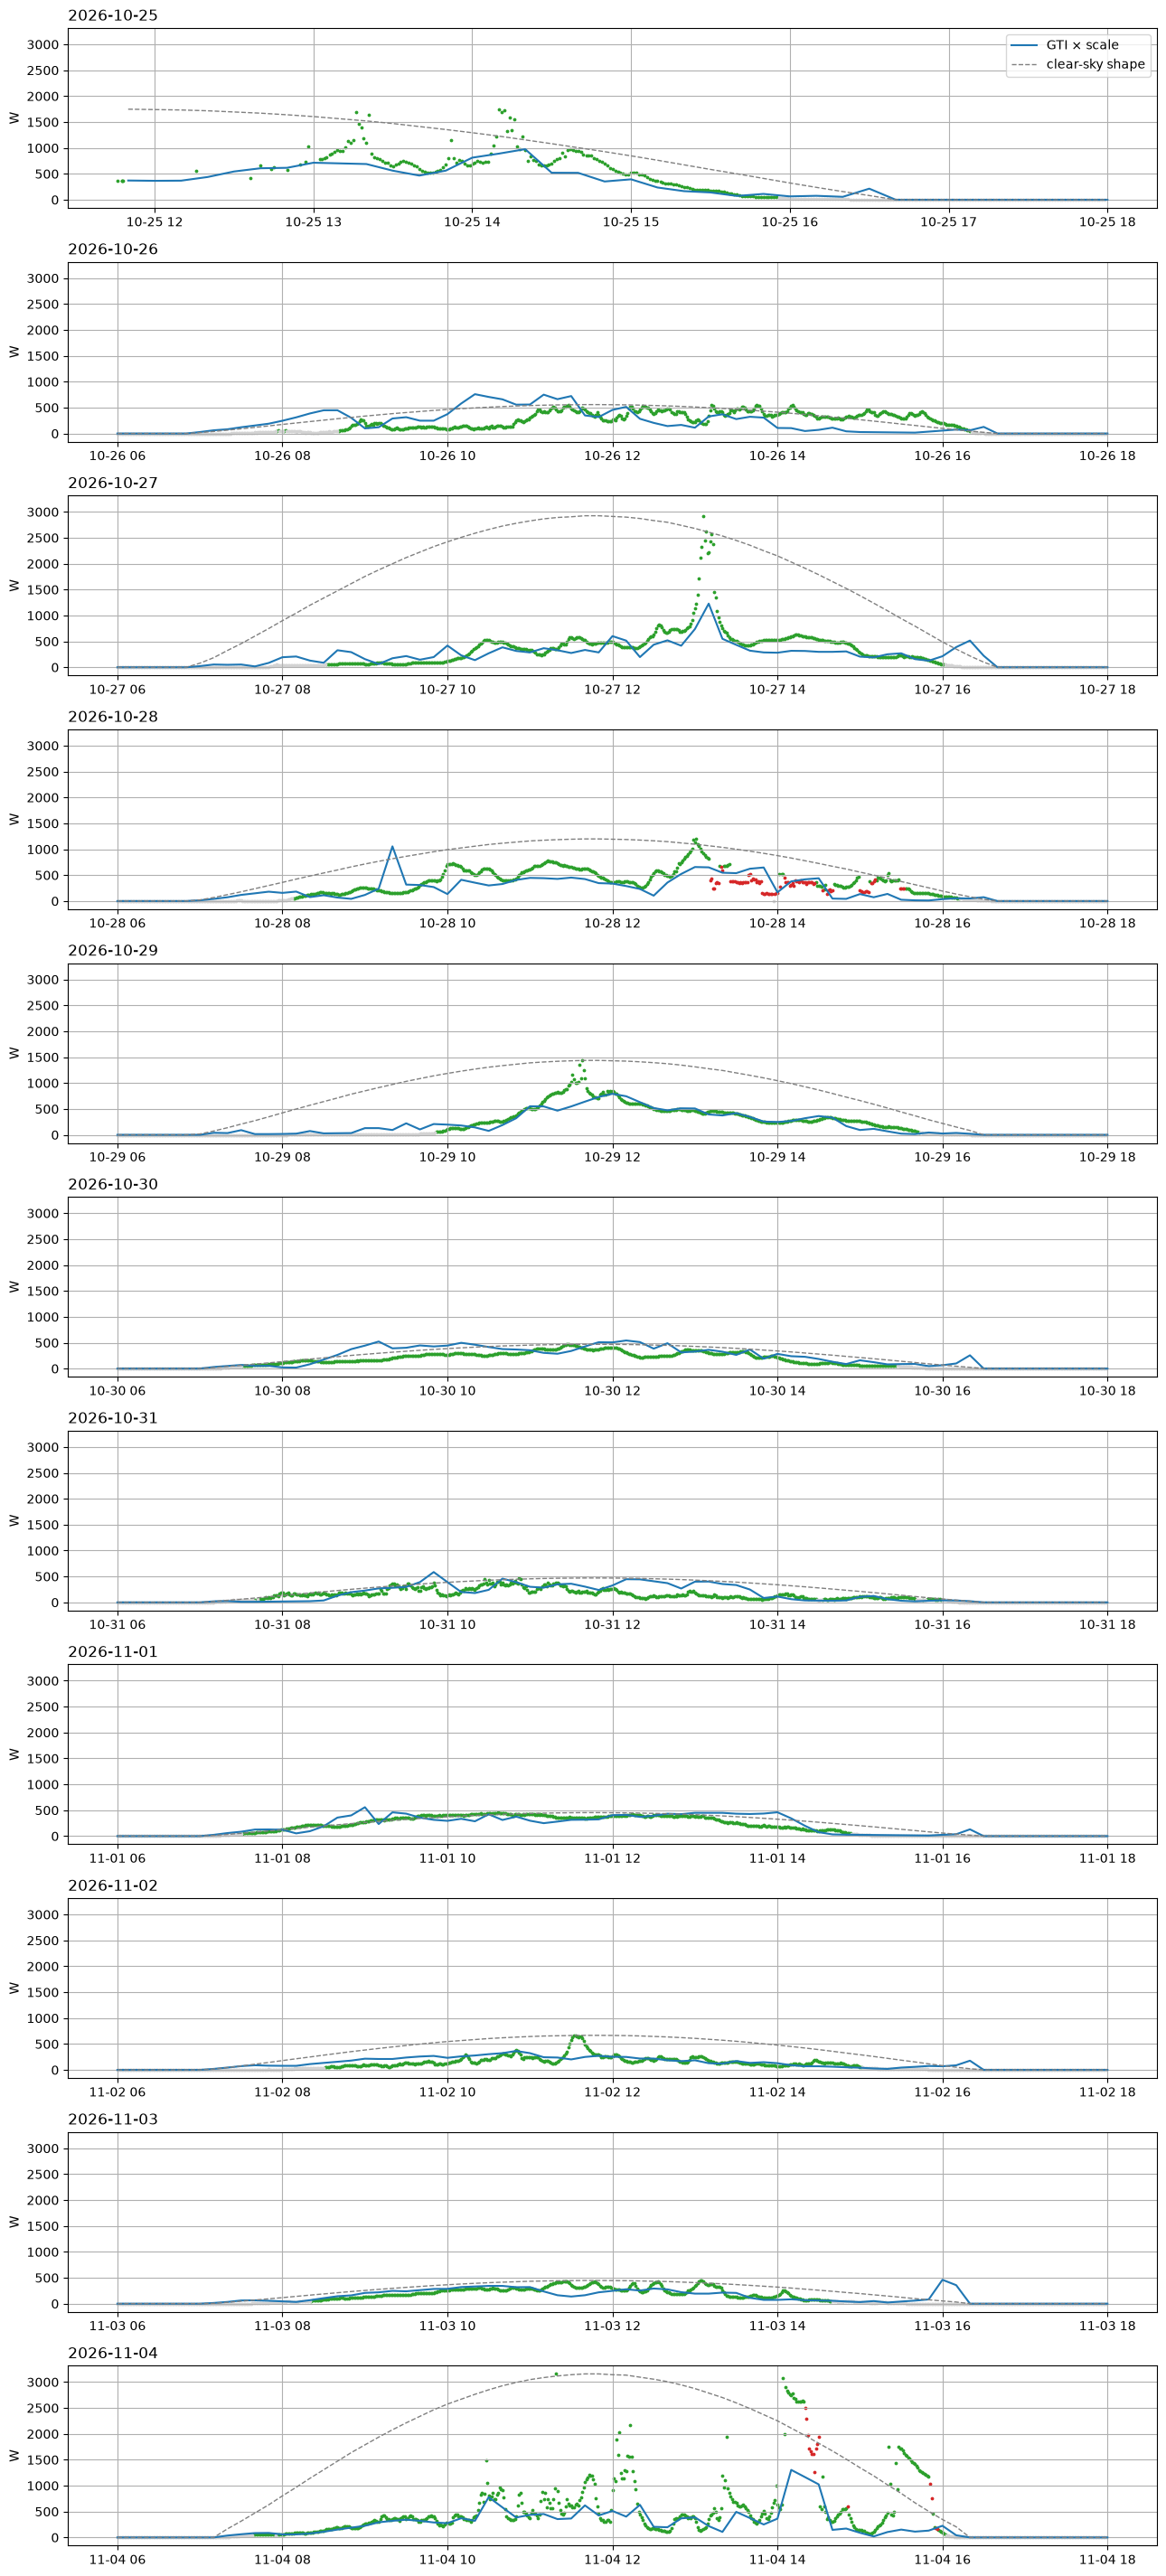

In [4]:
joined = load_joined()
unconstrained = joined[
    (joined["state"] == "unconstrained")
    & (joined["global_tilted_irradiance"] > 20)
]
scale = (
    unconstrained["solar_power_w"]
    / unconstrained["global_tilted_irradiance"]
).median()
print(f"median scale: {scale:.2f} W per W/m²")

days = sorted(set(local.index.date))
fig, axes = plt.subplots(
    len(days), 1, figsize=(13, 2.6 * len(days)), sharey=True,
)
sat_local = satellite.tz_convert(TZ)
for ax, day in zip(axes, days):
    d = local[local.index.date == day]
    d = d.between_time("06:00", "18:00")
    s = sat_local[sat_local.index.date == day].between_time("06:00", "18:00")
    for state, color in STATE_COLORS.items():
        part = d[d["state"] == state]
        ax.scatter(part.index, part["solar_power_w"], s=3, c=color)
    ax.plot(s["global_tilted_irradiance"] * scale, c="tab:blue",
            label="GTI × scale")
    ax.plot(s["shortwave_radiation_clear_sky"]
            / s["shortwave_radiation_clear_sky"].max()
            * d["solar_power_w"].max(),
            c="gray", ls="--", lw=1, label="clear-sky shape")
    ax.set_title(str(day), loc="left")
    ax.set_ylabel("W")
axes[0].legend(loc="upper right")
fig.tight_layout()